# CUDA Python Lab 01 — Student ID 240103179
Select **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**.
All empirical fields below are generated by a real GPU run; this unexecuted file contains no invented measurements.
The deliberately invalid kernel runs in a separate process so an illegal address does not poison this notebook's CUDA context.

In [1]:
import subprocess, sys, json, hashlib, math, time, html
from pathlib import Path
import numpy as np
import pandas as pd
from numba import cuda
from IPython.display import display, Markdown
STUDENT_ID = "240103179"
SEED = int(STUDENT_ID)
assert cuda.is_available(), "Enable T4 GPU in Runtime → Change runtime type first."
device = cuda.get_current_device()
GPU_NAME = device.name.decode('utf-8') if isinstance(device.name, bytes) else str(device.name)
assert 'T4' in GPU_NAME, f"This lab requires T4; allocated device: {GPU_NAME}"
results = {'student_id': STUDENT_ID}


## 1. Environment and hardware telemetry

In [2]:
smi = subprocess.run(['nvidia-smi'], capture_output=True, text=True, check=True).stdout
print(smi)
query = subprocess.run(['nvidia-smi', '--query-gpu=driver_version,name,memory.total', '--format=csv,noheader,nounits'], capture_output=True, text=True, check=True).stdout.strip()
driver, gpu_name, vram = [x.strip() for x in query.splitlines()[0].split(',')]
import re
cuda_version = re.search(r'CUDA Version:\s*([\d.]+)', smi).group(1)
telemetry = {'Driver version': driver, 'Driver-supported CUDA version': cuda_version,
 'GPU name': GPU_NAME, 'Total VRAM (MiB)': int(vram),
 'Compute capability': '.'.join(map(str, device.compute_capability)),
 'SM count': device.MULTIPROCESSOR_COUNT,
 'Max threads per block': device.MAX_THREADS_PER_BLOCK,
 'Max block dimensions': [device.MAX_BLOCK_DIM_X, device.MAX_BLOCK_DIM_Y, device.MAX_BLOCK_DIM_Z],
 'Warp size': device.WARP_SIZE}
results['telemetry'] = telemetry
results['nvidia_smi'] = smi
display(pd.DataFrame({'Field': list(telemetry), 'Observed value': [str(v) for v in telemetry.values()]}))


Thu Oct  8 07:10:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P0             25W /   70W |     105MiB /  15360MiB |      4%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

,Field,Observed value
0,Driver version,580.82.07
1,Driver-supported CUDA version,13.0
2,GPU name,Tesla T4
3,Total VRAM (MiB),15360
4,Compute capability,7.5
5,SM count,40
6,Max threads per block,1024
7,Max block dimensions,"[1024, 1024, 64]"
8,Warp size,32


## 2. CPU/GPU crossover experiment
The manual's timing method is preserved: host wall clock plus synchronization. “Kernel only” still includes host launch/synchronization overhead. GPU total includes transfers and allocation. CPU is skipped for N > 1,000,000 as allowed by the harness; no winner is claimed for those rows. Seed = Student ID.

In [3]:
def double_cpu_pure(arr):
    out = np.empty_like(arr)
    for i in range(len(arr)):
        out[i] = arr[i] * 2.0
    return out

@cuda.jit
def double_gpu_kernel(d_in, d_out):
    idx = cuda.grid(1)
    if idx < d_in.shape[0]:
        d_out[idx] = d_in[idx] * 2.0

def benchmark_run(N, student_id_seed=SEED):
    np.random.seed(student_id_seed)
    h_in = np.random.rand(N).astype(np.float32)
    cpu_time_ms = None
    if N <= 1_000_000:
        t0 = time.perf_counter()
        cpu_out = double_cpu_pure(h_in)
        cpu_time_ms = (time.perf_counter() - t0) * 1000
        np.testing.assert_allclose(cpu_out, h_in * 2, rtol=1e-6)
    threads_per_block = 256
    blocks_per_grid = (N + threads_per_block - 1) // threads_per_block
    d_warmup = cuda.to_device(np.ones(10, dtype=np.float32))
    double_gpu_kernel[1, 32](d_warmup, d_warmup)
    cuda.synchronize()
    t0 = time.perf_counter()
    d_in = cuda.to_device(h_in)
    d_out = cuda.device_array_like(d_in)
    double_gpu_kernel[blocks_per_grid, threads_per_block](d_in, d_out)
    h_out = d_out.copy_to_host()
    cuda.synchronize()
    gpu_total_ms = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter()
    double_gpu_kernel[blocks_per_grid, threads_per_block](d_in, d_out)
    cuda.synchronize()
    gpu_compute_ms = (time.perf_counter() - t0) * 1000
    np.testing.assert_allclose(h_out, h_in * 2, rtol=1e-6)
    return cpu_time_ms, gpu_total_ms, gpu_compute_ms

benchmark_rows = []
for N in [100, 1000, 10_000, 100_000, 1_000_000, 5_000_000, 10_000_000]:
    cpu_ms, total_ms, kernel_ms = benchmark_run(N)
    winner = 'CPU skipped' if cpu_ms is None else ('GPU' if total_ms < cpu_ms else 'CPU')
    benchmark_rows.append({'N': N, 'CPU ms': cpu_ms, 'GPU total ms': total_ms, 'GPU kernel only ms': kernel_ms, 'Winner': winner})
    print(f'N={N:,}: CPU={cpu_ms}, GPU total={total_ms:.6f} ms, kernel={kernel_ms:.6f} ms')
bench = pd.DataFrame(benchmark_rows)
display(bench)
results['benchmark'] = benchmark_rows
crossovers = [r['N'] for r in benchmark_rows if r['Winner'] == 'GPU']
CROSSOVER_N = min(crossovers) if crossovers else None
q1 = (f'The first measured array size where GPU total beats the pure Python CPU loop is N* = {CROSSOVER_N:,}. The exact threshold between sampled sizes was not measured.' if CROSSOVER_N else 'No crossover was observed among sizes with measured CPU times.')
r = benchmark_rows[0]
overhead_ms = r['GPU total ms'] - r['GPU kernel only ms']
overhead_pct = 100 * overhead_ms / r['GPU total ms']
q2 = (f"At N=100, GPU total is {r['GPU total ms']:.6f} ms and kernel-only is {r['GPU kernel only ms']:.6f} ms. Their difference is {overhead_ms:.6f} ms ({overhead_pct:.2f}% of total). Transfers, allocation and host/driver overhead dominate a small computation. These are separate noisy timings, so the difference is an estimate, not a direct PCIe measurement; 95% is not assumed. This CPU comparison uses a pure Python loop, not vectorized NumPy.")
results['crossover_N'] = CROSSOVER_N
results['analysis'] = {'Q1': q1, 'Q2': q2}
display(Markdown('**Q1.** '+q1+'\n\n**Q2.** '+q2))


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 40 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


N=100: CPU=0.08885099998678925, GPU total=6.632702 ms, kernel=0.134955 ms
N=1,000: CPU=0.6470139999805724, GPU total=3.017590 ms, kernel=0.113347 ms
N=10,000: CPU=6.670471000006728, GPU total=3.456258 ms, kernel=0.116202 ms
N=100,000: CPU=58.35736800000291, GPU total=3.109840 ms, kernel=0.136676 ms
N=1,000,000: CPU=784.320747999999, GPU total=3.708252 ms, kernel=0.178608 ms
N=5,000,000: CPU=None, GPU total=14.819731 ms, kernel=0.260222 ms
N=10,000,000: CPU=None, GPU total=26.768548 ms, kernel=0.475191 ms


,N,CPU ms,GPU total ms,GPU kernel only ms,Winner
0,100,0.088851,6.632702,0.134955,CPU
1,1000,0.647014,3.017590,0.113347,CPU
2,10000,6.670471,3.456258,0.116202,GPU
3,100000,58.357368,3.109840,0.136676,GPU
4,1000000,784.320748,3.708252,0.178608,GPU
5,5000000,NaN,14.819731,0.260222,CPU skipped
6,10000000,NaN,26.768548,0.475191,CPU skipped


**Q1.** The first measured array size where GPU total beats the pure Python CPU loop is N* = 10,000. The exact threshold between sampled sizes was not measured.

**Q2.** At N=100, GPU total is 6.632702 ms and kernel-only is 0.134955 ms. Their difference is 6.497747 ms (97.97% of total). Transfers, allocation and host/driver overhead dominate a small computation. These are separate noisy timings, so the difference is an estimate, not a direct PCIe measurement; 95% is not assumed. This CPU comparison uses a pure Python loop, not vectorized NumPy.

## 3.1 Missing guard: record actual console behavior

In [4]:
defective_source = r"""
import numpy as np
from numba import cuda
@cuda.jit
def defective_kernel(d_arr):
    idx = cuda.grid(1)
    d_arr[idx] = 999.0
try:
    N = 1000
    d_arr = cuda.to_device(np.zeros(N, dtype=np.float32))
    print('Launching defective kernel with 1024 threads on 1000-element array...', flush=True)
    defective_kernel[4, 256](d_arr)
    cuda.synchronize()
    print('Execution finished (or did it crash?). Checking host copy...', flush=True)
    h_result = d_arr.copy_to_host()
    print(f'Elements processed: {len(h_result)}. Last element: {h_result[-1]}', flush=True)
except Exception as exc:
    import traceback
    traceback.print_exc()
    raise
"""
proc = subprocess.run([sys.executable, '-c', defective_source], capture_output=True, text=True, timeout=120)
observed = f'Process exit code: {proc.returncode}\nSTDOUT:\n{proc.stdout}\nSTDERR:\n{proc.stderr}'
print(observed)
results['defective_observation'] = observed
results['defective_explanation'] = 'Four blocks of 256 launch 1024 threads. IDs 1000–1023 write beyond a 1000-element allocation. GPU code has no automatic Python IndexError; the run may silently complete or report an asynchronous illegal address. Successful completion does not establish memory safety.'


Process exit code: 0
STDOUT:
Launching defective kernel with 1024 threads on 1000-element array...
Execution finished (or did it crash?). Checking host copy...
Elements processed: 1000. Last element: 999.0

STDERR:
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))



## 3.2 Spatial thread coordinate inspector

In [5]:
@cuda.jit
def inspect_threads_kernel(log_block, log_thread, log_global, log_active, N):
    t_idx = cuda.threadIdx.x
    b_idx = cuda.blockIdx.x
    g_idx = cuda.grid(1)
    if g_idx < log_block.shape[0]:
        log_block[g_idx] = b_idx
        log_thread[g_idx] = t_idx
        log_global[g_idx] = g_idx
        log_active[g_idx] = 1 if g_idx < N else 0
N, threads_per_block = 37, 8
blocks_per_grid = (N + threads_per_block - 1) // threads_per_block
logs = [cuda.device_array(blocks_per_grid * threads_per_block, dtype=np.int32) for _ in range(4)]
inspect_threads_kernel[blocks_per_grid, threads_per_block](*logs, N)
cuda.synchronize()
b, t, g, a = [x.copy_to_host() for x in logs]
thread_table = pd.DataFrame({'Global ID': g, 'Block ID': b, 'Thread ID': t, 'Status': ['ACTIVE' if x else 'IDLE (GUARDED)' for x in a]})
display(thread_table.iloc[32:40])
geometry = {'Total blocks': blocks_per_grid, 'Total hardware threads': len(g), 'Active threads': int(a.sum()), 'Idle guarded threads': int((a == 0).sum())}
assert list(geometry.values()) == [5, 40, 37, 3]
results['thread_geometry'] = geometry
results['thread_coordinates'] = thread_table.iloc[32:40].to_dict('records')
print(geometry)


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 5 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


,Global ID,Block ID,Thread ID,Status
32,32,4,0,ACTIVE
33,33,4,1,ACTIVE
34,34,4,2,ACTIVE
35,35,4,3,ACTIVE
36,36,4,4,ACTIVE
37,37,4,5,IDLE (GUARDED)
38,38,4,6,IDLE (GUARDED)
39,39,4,7,IDLE (GUARDED)


{'Total blocks': 5, 'Total hardware threads': 40, 'Active threads': 37, 'Idle guarded threads': 3}


## 4. Race condition and atomic reduction
Use 50,000 ones as specified in the mandatory table. Reset the accumulator to zero before every trial. Warm up both kernels before timing.

In [6]:
@cuda.jit
def naive_sum_kernel(d_arr, d_total):
    idx = cuda.grid(1)
    if idx < d_arr.shape[0]:
        d_total[0] += d_arr[idx]
@cuda.jit
def atomic_sum_kernel(d_arr, d_total):
    idx = cuda.grid(1)
    if idx < d_arr.shape[0]:
        cuda.atomic.add(d_total, 0, d_arr[idx])
N_SUM = 50_000
sum_input = cuda.to_device(np.ones(N_SUM, dtype=np.float32))
sum_total = cuda.to_device(np.zeros(1, dtype=np.float32))
sum_blocks, sum_threads = (N_SUM + 255) // 256, 256
for kernel in (naive_sum_kernel, atomic_sum_kernel):
    sum_total.copy_to_device(np.zeros(1, dtype=np.float32))
    kernel[sum_blocks, sum_threads](sum_input, sum_total)
    cuda.synchronize()
def sum_trial(kernel):
    sum_total.copy_to_device(np.zeros(1, dtype=np.float32))
    cuda.synchronize()
    t0 = time.perf_counter()
    kernel[sum_blocks, sum_threads](sum_input, sum_total)
    cuda.synchronize()
    elapsed_ms = (time.perf_counter() - t0) * 1000
    value = float(sum_total.copy_to_host()[0])
    return value, elapsed_ms
race_rows = []
for trial in range(1, 6):
    value, elapsed_ms = sum_trial(naive_sum_kernel)
    race_rows.append({'Trial': trial, 'Target sum': float(N_SUM), 'Naive output': value, 'Lost updates': N_SUM - value, 'Naive ms': elapsed_ms})
atomic_value, atomic_ms = sum_trial(atomic_sum_kernel)
naive_ms = float(np.mean([r['Naive ms'] for r in race_rows]))
assert atomic_value == 50_000.0
results['race_trials'] = race_rows
results['atomic'] = {'Output': atomic_value, 'Exactly 50000': atomic_value == 50_000.0, 'Naive mean ms (5 trials)': naive_ms, 'Atomic ms (1 trial)': atomic_ms}
results['atomic_explanation'] = 'The naive read-modify-write is not indivisible, so concurrent writes can overwrite increments. Atomic add serializes contending updates to the same address and preserves all additions. This contention can cost time; a slowdown is measured, not guaranteed. Host wall-clock timing includes launch/synchronization overhead and the timing comparison is noisy.'
display(pd.DataFrame(race_rows))
print(results['atomic'])
print(results['atomic_explanation'])


,Trial,Target sum,Naive output,Lost updates,Naive ms
0,1,50000.0,2.0,49998.0,0.106273
1,2,50000.0,2.0,49998.0,0.076136
2,3,50000.0,2.0,49998.0,0.085244
3,4,50000.0,2.0,49998.0,0.066960
4,5,50000.0,2.0,49998.0,0.065060


{'Output': 50000.0, 'Exactly 50000': True, 'Naive mean ms (5 trials)': 0.07993460000648156, 'Atomic ms (1 trial)': 0.24732099998914236}
The naive read-modify-write is not indivisible, so concurrent writes can overwrite increments. Atomic add serializes contending updates to the same address and preserves all additions. This contention can cost time; a slowdown is measured, not guaranteed. Host wall-clock timing includes launch/synchronization overhead and the timing comparison is noisy.


## 5. 2D radial vignette

{'Blocks X': 64, 'Blocks Y': 64, 'Total blocks': 4096, 'Center pixel (512,512)': 1.0, 'Corner pixel (0,0)': 0.0}


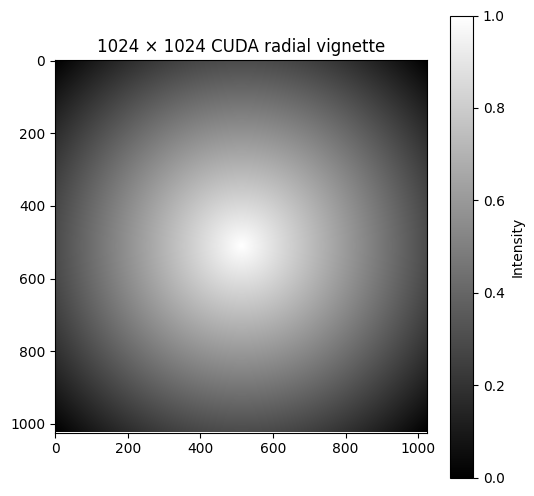

In [7]:
@cuda.jit
def radial_vignette_2d(d_canvas, width, height, center_x, center_y):
    x, y = cuda.grid(2)
    if x < width and y < height:
        dx = float(x - center_x)
        dy = float(y - center_y)
        dist = math.sqrt(dx * dx + dy * dy)
        max_dist = math.sqrt(float(center_x**2 + center_y**2))
        intensity = 1.0 - dist / max_dist
        if intensity < 0.0:
            intensity = 0.0
        d_canvas[y, x] = intensity
WIDTH, HEIGHT = 1024, 1024
threads_2d = (16, 16)
blocks_2d = ((WIDTH + 15) // 16, (HEIGHT + 15) // 16)
d_canvas = cuda.to_device(np.zeros((HEIGHT, WIDTH), dtype=np.float32))
radial_vignette_2d[blocks_2d, threads_2d](d_canvas, WIDTH, HEIGHT, WIDTH // 2, HEIGHT // 2)
cuda.synchronize()
result_canvas = d_canvas.copy_to_host()
image_geometry = {'Blocks X': blocks_2d[0], 'Blocks Y': blocks_2d[1], 'Total blocks': blocks_2d[0] * blocks_2d[1], 'Center pixel (512,512)': float(result_canvas[512,512]), 'Corner pixel (0,0)': float(result_canvas[0,0])}
assert image_geometry['Center pixel (512,512)'] == 1.0
assert image_geometry['Corner pixel (0,0)'] == 0.0
results['image_geometry'] = image_geometry
print(image_geometry)
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.imshow(result_canvas, cmap='gray', vmin=0, vmax=1)
plt.title('1024 × 1024 CUDA radial vignette')
plt.colorbar(label='Intensity')
plt.savefig('CUDA_Lab01_240103179_vignette.png', bbox_inches='tight', dpi=150)
plt.show()


## 6. Official verification checksum
The official buffer/ID/device/crossover hashing algorithm is preserved. A token is generated only after real GPU execution; if no crossover was observed, the notebook stops rather than inserting an example value.

In [8]:
def generate_lab_checksum(student_id_str, d_canvas, exp_table_crossover):
    h = hashlib.sha256()
    h.update(student_id_str.strip().encode('utf-8'))
    name = cuda.get_current_device().name
    h.update(name if isinstance(name, bytes) else name.encode('utf-8'))
    h.update(d_canvas.copy_to_host()[:10, :10].tobytes())
    h.update(str(exp_table_crossover).encode('utf-8'))
    digest = h.hexdigest()[:16].upper()
    print('=' * 60)
    print(f'OFFICIAL VERIFICATION CHECKSUM TOKEN: {digest}')
    print('=' * 60)
    return digest
assert CROSSOVER_N is not None, 'No empirical crossover found. Extend CPU benchmark before generating a token.'
TOKEN = generate_lab_checksum(STUDENT_ID, d_canvas, CROSSOVER_N)
results['verification_token'] = TOKEN


OFFICIAL VERIFICATION CHECKSUM TOKEN: 31303CE270488FBD


## 7. Generate completed report and raw results

In [9]:
from datetime import datetime, timezone
results['run_time_utc'] = datetime.now(timezone.utc).isoformat()
base = f'CUDA_Lab01_{STUDENT_ID}'
Path(base + '_results.json').write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
def paragraph(s):
    return '<p>' + html.escape(str(s)) + '</p>'
def table(data):
    if isinstance(data, dict):
        return pd.DataFrame({'Field': list(data), 'Value': [str(v) for v in data.values()]}).to_html(index=False, escape=True)
    return pd.DataFrame(data).to_html(index=False, escape=True, na_rep='Skipped', float_format=lambda x: f'{x:.6f}')
report = '<!doctype html><html><head><meta charset="utf-8"><title>CUDA Lab Report</title><style>body{font:14px Arial;max-width:1000px;margin:35px auto;color:#182638}table{border-collapse:collapse;width:100%;margin:15px 0}td,th{border:1px solid #bbb;padding:7px;text-align:left}th{background:#e9eff6}pre{white-space:pre-wrap;font-size:11px}h1,h2{color:#17456b}@media print{body{margin:10mm}table{font-size:11px}}</style></head><body>'
report += '<h1>CUDA Python Lab 01 — Completed Experimental Report</h1>'
report += paragraph('Student ID: ' + STUDENT_ID) + paragraph('Actual run timestamp (UTC): '+results['run_time_utc'])
report += '<h2>1. Hardware telemetry</h2>'+table(telemetry)
report += '<h2>2. Benchmark</h2>'+table(benchmark_rows)+paragraph(q1)+paragraph(q2)
report += '<h2>3.1 Missing guard observation</h2><pre>'+html.escape(observed)+'</pre>'+paragraph(results['defective_explanation'])
report += '<h2>3.2 Thread geometry</h2>'+table(geometry)+table(results['thread_coordinates'])
report += '<h2>4. Race condition</h2>'+table(race_rows)+table(results['atomic'])+paragraph(results['atomic_explanation'])
report += '<h2>5. 2D grid</h2>'+table(image_geometry)
report += '<h2>6. Official verification token</h2>'+paragraph(TOKEN)
report += '<h2>Submission</h2>'+paragraph('Save this executed notebook with all outputs visible, download it as .ipynb, and submit the notebook plus this report/task sheet according to your instructor’s requirements. Student name must be entered by the student if required.')
report += '</body></html>'
Path(base + '_report.html').write_text(report, encoding='utf-8')
print('Generated:', base+'_report.html', base+'_results.json', base+'_vignette.png')
# In Colab, the files can be downloaded from the Files sidebar.
# To print a PDF report, open the downloaded HTML and choose Print → Save as PDF.
display(Markdown('**Completed token:** `'+TOKEN+'`'))


Generated: CUDA_Lab01_240103179_report.html CUDA_Lab01_240103179_results.json CUDA_Lab01_240103179_vignette.png


**Completed token:** `31303CE270488FBD`